# 1D t-J echo-contrast simulation

This notebook simulates the spin-echo Ramsey contrast of a 1D chain of nuclear-spin-polarized ⁸⁷Sr atoms in a harmonic gradient. It asks when the initial contrast collapse scales as $t_x^2$ (superexchange) and when it scales as $t_x$ (hole hopping).

Everything is computed here, with no fitting parameters: $t_x$, $U$, the gradient $\kappa$, the offset $\delta_0$ and the filling are inputs. The notebook makes four kinds of plot:

1. contrast curves against $T$, $T t_x$ and $T\cdot 4t_x^2/U$ for several loadings;
2. a demonstration of how the collapse exponent is chosen;
3. the best exponent against uniform filling, per offset;
4. the 2D exponent map: $\delta_0$ against z-averaged column filling, for three fit windows.

**Run time.** The full run ($L = 9$) evolves 63 parameter sets, about 40 s each on 2 cores, so about 45 min. Results are cached in `runs_L9/`, so a rerun only redoes the plots. Set `QUICK = True` for a $L = 5$ test run of about 1 min.

In [1]:
import itertools, os, time
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.optimize import brentq

QUICK = False                      # True: L = 5 test run, about 1 min

L = 5 if QUICK else 9              # chain length (sites); trap centre on the middle site
U = 800.0                          # on-site e-g interaction (Hz)
KAPPA = 50.0                       # harmonic gradient: bond offset grows by KAPPA per site (Hz/site)
PHI = 1.165 * np.pi                # clock spin-orbit phase per site, k_c a
THETA0 = 0.7 * np.pi               # initial tip angle
ROI_HALF = 2                       # readout sites |x| <= 2 (central 5 sites, about ±1.1 um)
TX = [10, 12.5, 15, 17.5, 20, 22.5, 25, 27.5, 30]      # tunneling values (Hz)
D0_MAP = [0, 25] if QUICK else [0, 12.5, 25, 50, 75, 100]   # offsets for the exponent map (Hz)
D0_ALL = sorted(set(D0_MAP + [0, 12.5, 25, 300])) if not QUICK else [0, 25, 300]
T = np.concatenate([[0], np.logspace(-4, np.log10(4), 60)])  # one-arm dark time (s)
C0 = np.sin(THETA0)                # contrast right after the tip pulse
CACHE = f"runs_L{L}"
print(f"L = {L}, {len(TX)} t_x values x {len(D0_ALL)} offsets = {len(TX) * len(D0_ALL)} runs")

L = 9, 9 t_x values x 7 offsets = 63 runs


## 1. Model

Each atom is a pseudo-spin: $\downarrow = g$ ($^1S_0$), $\uparrow = e$ ($^3P_0$). The chain is a plain t-J model with a site-dependent potential, in Hz ($h = 1$). Sites sit at integer positions $x_j$, with the trap centre on $x = 0$:

$$H = -t\sum_{j,\sigma}\mathcal{P}\left(c^\dagger_{j+1,\sigma}c_{j,\sigma} + \mathrm{h.c.}\right)\mathcal{P} + \sum_j V_j n_j + \sum_j J_j\left(\mathbf{S}_j\cdot\mathbf{S}_{j+1} - \tfrac14 n_j n_{j+1}\right)$$

$\mathcal{P}$ removes doubly occupied sites. The potential is harmonic plus a uniform tilt $\delta_0$, so the offset across bond $(j, j+1)$ grows linearly along the chain:

$$V_j = \tfrac{\kappa}{2}x_j^2 + \delta_0 x_j,\qquad \Delta_j = V_{j+1} - V_j = \kappa\left(x_j + \tfrac12\right) + \delta_0$$

The tilt only moves the trap minimum to $x = -\delta_0/\kappa$. Each bond has its own superexchange, from virtual hops costing $U - \Delta_j$ and $U + \Delta_j$:

$$J_j = \frac{2t^2}{U - \Delta_j} + \frac{2t^2}{U + \Delta_j} = \frac{4t^2U}{U^2 - \Delta_j^2}$$

**Spin-orbit phase.** The gauge transformation $c_{j\uparrow}\to e^{i\varphi x_j}c_{j\uparrow}$ moves the clock laser's phase $\varphi = k_c a$ out of the hopping and into the pulses. $H$ is then real and SU(2)-symmetric, and each pulse acts on site $j$ with laser phase $\varphi x_j$ (section 3).

## 2. Basis and matrix construction

$H$ conserves the atom number $N$ and the number of $e$ atoms $m$, so it is built and diagonalized one $(N, m)$ sector at a time. A basis state lists the occupied sites and the spin of each atom, left to right:

$$|p_1 < p_2 < \dots < p_N;\; s_1 s_2\dots s_N\rangle,\qquad \dim(N, m) = \binom{L}{N}\binom{N}{m}$$

**No fermionic signs.** In 1D with open ends and nearest-neighbour hops, an atom never passes another, so the spin order never changes and every sign is $+1$.

Matrix elements:

1. Potential (diagonal): $\sum_k V_{p_k}$.
2. Hopping ($-t$): atom $k$ moves to an empty neighbouring site; the spin string is unchanged.
3. Exchange, only on bonds with both sites occupied: parallel spins give 0; antiparallel spins give $-J_j/2$ on the diagonal and $+J_j/2$ for the swap $\uparrow\downarrow\leftrightarrow\downarrow\uparrow$.

In [2]:
class Chain:
    # Open 1D t-J chain in a harmonic gradient. Energies in Hz.
    def __init__(self, L, t, U, kappa=KAPPA, delta0=0.0, phi=PHI, theta0=THETA0, roi_half=ROI_HALF):
        self.L, self.t, self.U, self.kappa, self.delta0 = L, t, U, kappa, delta0
        self.phi, self.theta0 = phi, theta0
        self.x = np.arange(L) - (L - 1) / 2.0           # site positions; trap centre on a site
        self.V = 0.5 * kappa * self.x**2 + delta0 * self.x
        self.D = np.diff(self.V)                         # bond offsets Delta_j
        if np.any(np.abs(self.D) >= U):
            raise ValueError(f"a bond offset reaches U (max |Delta| = {np.abs(self.D).max():.0f} Hz)")
        self.J = 4 * t**2 * U / (U**2 - self.D**2)
        self.roi = np.abs(self.x) <= roi_half + 1e-9

    def sector(self, N, m):
        confs = list(itertools.combinations(range(self.L), N))                  # occupied sites
        spins = [sum(1 << k for k in ks) for ks in itertools.combinations(range(N), m)]  # bit k = atom k is e
        return confs, spins, {c: i for i, c in enumerate(confs)}, {s: i for i, s in enumerate(spins)}

    def hamiltonian(self, N, m):
        confs, spins, cidx, sidx = self.sector(N, m)
        ns = len(spins)
        H = np.zeros((len(confs) * ns,) * 2)
        for ci, c in enumerate(confs):
            pot = self.V[list(c)].sum()
            occ = set(c)
            hops = [cidx[tuple(sorted(c[:k] + (q,) + c[k + 1:]))]
                    for k, p in enumerate(c) for q in (p - 1, p + 1)
                    if 0 <= q < self.L and q not in occ]
            for si, s in enumerate(spins):
                i = ci * ns + si
                H[i, i] += pot                                        # 1. potential
                for cj in hops:
                    H[cj * ns + si, i] += -self.t                     # 2. hopping, spin string kept
                for k in range(N - 1):                                # 3. exchange on occupied bonds
                    if c[k + 1] == c[k] + 1 and ((s >> k) & 1) != ((s >> (k + 1)) & 1):
                        b = c[k]
                        H[i, i] += -self.J[b] / 2
                        H[ci * ns + sidx[s ^ (1 << k) ^ (1 << (k + 1))], i] += self.J[b] / 2
        return H

### Worked example: 3 sites, 2 atoms, one $e$

Sector $N = 2$, $m = 1$ on a 3-site chain: $3\times2 = 6$ states. With $t = 20$ Hz, $U = 800$ Hz, $\kappa = 50$ Hz/site, $\delta_0 = 0$: $x = -1, 0, 1$; $V = 25, 0, 25$ Hz; $\Delta = -25, +25$ Hz; $J = 2.002$ Hz on both bonds.

| State | Occupied sites $x$ | Spins, left to right | $V$ sum (Hz) |
|---|---|---|---|
| 1 | −1, 0 | ↑↓ | 25 |
| 2 | −1, 0 | ↓↑ | 25 |
| 3 | −1, +1 | ↑↓ | 50 |
| 4 | −1, +1 | ↓↑ | 50 |
| 5 | 0, +1 | ↑↓ | 25 |
| 6 | 0, +1 | ↓↑ | 25 |

Expected: diagonal $25 - J/2 = 23.999$ for neighbouring pairs and $50$ for the separated pair; $+J/2 = 1.001$ for the exchange swap; $-t = -20$ for each hop. The cell below builds it with the code above and checks it.

In [3]:
ex = Chain(3, t=20, U=800, delta0=0)
H3 = ex.hamiltonian(2, 1)
print("Delta =", ex.D, "Hz;  J =", np.round(ex.J, 4), "Hz")
np.set_printoptions(precision=3, suppress=True)
print(H3)
j2 = ex.J[0] / 2
expected = np.array([[25 - j2, j2, -20, 0, 0, 0],
                     [j2, 25 - j2, 0, -20, 0, 0],
                     [-20, 0, 50, 0, -20, 0],
                     [0, -20, 0, 50, 0, -20],
                     [0, 0, -20, 0, 25 - j2, j2],
                     [0, 0, 0, -20, j2, 25 - j2]])
assert np.allclose(H3, expected), "worked example does not match"
print("matches the hand-built matrix")

Delta = [-25.  25.] Hz;  J = [2.002 2.002] Hz
[[ 23.999   1.001 -20.      0.      0.      0.   ]
 [  1.001  23.999   0.    -20.      0.      0.   ]
 [-20.      0.     50.      0.    -20.      0.   ]
 [  0.    -20.      0.     50.      0.    -20.   ]
 [  0.      0.    -20.      0.     23.999   1.001]
 [  0.      0.      0.    -20.      1.001  23.999]]
matches the hand-built matrix


## 3. Initial state, pulses, time evolution and readout

**Initial state.** Each run starts from one occupation pattern $c$: atoms on definite sites, all in $g$. The tip pulse ($\theta_0 = 0.7\pi$) makes a product state with each atom's site phase:

$$|\psi_c(0)\rangle = \bigotimes_{k=1}^N\left[\cos\tfrac{\theta_0}{2}|{\downarrow}\rangle_{p_k} - i\sin\tfrac{\theta_0}{2}e^{i\varphi x_{p_k}}|{\uparrow}\rangle_{p_k}\right]$$

**Pulses.** Instantaneous rotations, $R_j(\theta) = \exp\left[-\tfrac{i\theta}{2}\left(e^{i\varphi x_j}\sigma_j^+ + e^{-i\varphi x_j}\sigma_j^-\right)\right]$. The echo $\pi$ pulse flips every spin: $(c, s)$ in sector $m$ goes to $(c, \bar s)$ in sector $N - m$ with phase $\prod_k(-i)e^{\pm i\varphi x_k}$ ($+$ for $\downarrow\to\uparrow$). It is a relabelling with phases, not a matrix product.

**Evolution.** Per sector, $U(T) = V e^{-2\pi i E T}V^\top$ from the eigenvectors $V$ and eigenvalues $E$. The sequence is tip – $T$ – $\pi$ – $T$ – readout, so

$$|\psi_c(2T)\rangle = U(T)\,R_\pi\,U(T)\,|\psi_c(0)\rangle .$$

**Readout.** The readout $\pi/2$ pulse is scanned in phase; the fringe amplitude is the transverse spin in the frame of the pulses, summed over the readout region (ROI):

$$O = \sum_{j\in\mathrm{ROI}} e^{-i\varphi x_j}\sigma_j^-,\qquad C(T) = \frac{2\left|\sum_c w_c\langle O\rangle_c\right|}{\sum_c w_c\langle n_\mathrm{ROI}\rangle_c}$$

The complex signals of all patterns are summed before the modulus, as the measurement does. All $2^L$ patterns are evolved once and stored, so any loading is just a set of weights $w_c$ (section 4).

In [4]:
def run_N(ch, N, times):
    # Signals for every occupation pattern with N atoms: <O>(pattern, T) and <n_ROI>(pattern, T).
    L, phi, th = ch.L, ch.phi, ch.theta0
    confs = list(itertools.combinations(range(L), N))
    nconf, nT = len(confs), len(times)
    masks = np.array([sum(1 << p for p in c) for c in confs])
    if N == 0:
        return masks, np.zeros((1, nT), complex), np.zeros((1, nT))
    sec = {}
    for m in range(N + 1):
        _, spins, _, sidx = ch.sector(N, m)
        E, Vm = np.linalg.eigh(ch.hamiltonian(N, m))
        sec[m] = dict(E=E, V=Vm, spins=spins, sidx=sidx, ns=len(spins))
    xs = np.array([ch.x[list(c)] for c in confs])            # (pattern, atom) positions
    inroi = np.array([ch.roi[list(c)] for c in confs])
    nroi_conf = inroi.sum(1).astype(float)
    cols = np.arange(nconf)

    # tipped initial states, written in each sector's eigenbasis
    W = {}
    for m, S in sec.items():
        Psi = np.zeros((nconf * S["ns"], nconf), complex)
        for si, s in enumerate(S["spins"]):
            up = np.array([(s >> k) & 1 for k in range(N)], bool)
            amp = np.cos(th / 2) ** (N - m) * (-1j * np.sin(th / 2)) ** m * np.exp(1j * phi * (xs * up).sum(1))
            Psi[cols * S["ns"] + si, cols] = amp
        W[m] = S["V"].T @ Psi

    # echo pi pulse: (pattern, s) in sector m -> (pattern, ~s) in sector N-m, with phase
    full = (1 << N) - 1
    echo = {}
    for m, S in sec.items():
        src, dst, ph = [], [], []
        for si, s in enumerate(S["spins"]):
            up = np.array([(s >> k) & 1 for k in range(N)], bool)
            src.append(cols * S["ns"] + si)
            dst.append(cols * sec[N - m]["ns"] + sec[N - m]["sidx"][full ^ s])
            ph.append((-1j) ** N * np.exp(1j * phi * (xs * np.where(up, -1, 1)).sum(1)))
        echo[m] = tuple(map(np.concatenate, (src, dst, ph)))

    # readout operator O = sum_ROI e^{-i phi x} sigma^-: sector m -> m-1
    Oop = {}
    for m, S in sec.items():
        if m == 0:
            continue
        src, dst, cf = [], [], []
        for si, s in enumerate(S["spins"]):
            for k in range(N):
                if (s >> k) & 1:
                    src.append(cols * S["ns"] + si)
                    dst.append(cols * sec[m - 1]["ns"] + sec[m - 1]["sidx"][s ^ (1 << k)])
                    cf.append(np.where(inroi[:, k], np.exp(-1j * phi * xs[:, k]), 0.0))
        Oop[m] = tuple(map(np.concatenate, (src, dst, cf)))
    nroi_row = {m: np.repeat(nroi_conf, S["ns"]) for m, S in sec.items()}

    Oexp, nexp = np.zeros((nconf, nT), complex), np.zeros((nconf, nT))
    for it, Tt in enumerate(times):
        Yp = {m: np.zeros((nconf * sec[m]["ns"], nconf), complex) for m in sec}
        for m, S in sec.items():                                   # evolve T, then echo
            Y = S["V"] @ (np.exp(-2j * np.pi * S["E"] * Tt)[:, None] * W[m])
            src, dst, ph = echo[m]
            Yp[N - m][dst] = ph[:, None] * Y[src]
        F = {m: S["V"] @ (np.exp(-2j * np.pi * S["E"] * Tt)[:, None] * (S["V"].T @ Yp[m]))
             for m, S in sec.items()}                              # evolve T again
        for m in sec:                                              # readout
            nexp[:, it] += (np.abs(F[m]) ** 2 * nroi_row[m][:, None]).sum(0)
            if m > 0:
                src, dst, cf = Oop[m]
                Oexp[:, it] += (np.conj(F[m - 1][dst]) * cf[:, None] * F[m][src]).sum(0)
    return masks, Oexp, nexp


def run_all(ch, times):
    # Signals for all 2^L occupation patterns, indexed by bitmask (bit j = site j occupied).
    O = np.zeros((1 << ch.L, len(times)), complex)
    n = np.zeros((1 << ch.L, len(times)))
    for N in range(ch.L + 1):
        masks, o, nn = run_N(ch, N, times)
        O[masks], n[masks] = o, nn
    return O, n

## 4. Loading and z-averaging

The motional state is a classical mixture of occupation patterns. For independent site filling $n_j$, pattern $c$ (occupations $o_j\in\{0,1\}$) has weight $w_c = \prod_j n_j^{o_j}(1-n_j)^{1-o_j}$.

**z-average.** Imaging along $z$ sums many chains in each ROI column. Chain filling follows a capped Gaussian, $n(z) = \min\left(1,\, n_\mathrm{peak}e^{-z^2/2\sigma_z^2}\right)$, and the column's weights are $\sum_z w_c(n(z))$. The x-axis "column filling" is the atom-weighted mean $\sum n^2/\sum n$; it does not depend on $\sigma_z$. Every chain has the same $t_x$, $U$, $\kappa$ and $\delta_0$.

In [5]:
def occupancy(L):
    m = np.arange(1 << L)
    return ((m[:, None] >> np.arange(L)) & 1).astype(bool)

def weights(L, nsite):
    # independent site filling: scalar or per-site array
    nsite = np.broadcast_to(np.asarray(nsite, float), (L,))
    return np.prod(np.where(occupancy(L), nsite, 1 - nsite), axis=1)

def contrast(O, n, w):
    # C(T) / C(0) for pattern weights w
    with np.errstate(invalid="ignore", divide="ignore"):
        return 2 * np.abs(w @ O) / (w @ n) / C0

ZZ = np.linspace(-6, 6, 1201)          # z in units of sigma_z

def z_profile(n_peak):
    return np.minimum(1.0, n_peak * np.exp(-ZZ**2 / 2))

def atom_mean(n_peak):
    n = z_profile(n_peak)
    return (n**2).sum() / n.sum()

def column_weights(L, column_filling):
    # weights for a z-averaged column with the given atom-weighted mean filling
    n_peak = brentq(lambda p: atom_mean(p) - column_filling, 1e-3, 200)
    return sum(weights(L, n) for n in z_profile(n_peak) if n > 1e-4)

print("column filling 0.5 needs n_peak =", round(brentq(lambda p: atom_mean(p) - 0.5, 1e-3, 200), 4), "(= 1/sqrt 2)")

column filling 0.5 needs n_peak = 0.7071 (= 1/sqrt 2)


## 5. Checks

- $\varphi = 0$: the uniform pulses commute with the SU(2)-symmetric $H$, so $C(T) = C(0)$ for any filling.
- $t = 0$ (so $J = 0$): nothing evolves.
- One atom on a resonant bond ($\delta_0 = 25$ Hz puts $\Delta = 0$ between $x = -1$ and $0$): must match a direct single-particle calculation.

In [6]:
Tc = np.array([0, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0])
O, n = run_all(Chain(7, t=30, U=U, phi=0.0), Tc)
print("phi = 0:", np.round(contrast(O, n, weights(7, 0.7)), 8))
O, n = run_all(Chain(7, t=0.0, U=U), Tc)
print("t = 0:  ", np.round(contrast(O, n, weights(7, 0.7)), 8))

ch = Chain(7, t=30, U=U, delta0=25.0)
_, o1, n1 = run_N(ch, 1, Tc)
i0 = list(itertools.combinations(range(7), 1)).index((3,))      # atom on the centre site
many_body = 2 * np.abs(o1[i0]) / n1[i0] / C0
H1 = np.diag(ch.V) - ch.t * (np.eye(7, k=1) + np.eye(7, k=-1))
E1, V1 = np.linalg.eigh(H1)
U1 = lambda tt: V1 @ np.diag(np.exp(-2j * np.pi * E1 * tt)) @ V1.T
direct = []
for tt in Tc:
    d = np.zeros(7, complex); d[3] = np.cos(THETA0 / 2)
    u = np.zeros(7, complex); u[3] = -1j * np.sin(THETA0 / 2) * np.exp(1j * PHI * ch.x[3])
    d, u = U1(tt) @ d, U1(tt) @ u
    d, u = -1j * np.exp(-1j * PHI * ch.x) * u, -1j * np.exp(1j * PHI * ch.x) * d   # echo
    d, u = U1(tt) @ d, U1(tt) @ u
    direct.append(2 * abs(np.sum(np.conj(d) * np.exp(-1j * PHI * ch.x) * u * ch.roi))
                  / np.sum((abs(d)**2 + abs(u)**2) * ch.roi) / C0)
print("one atom, many-body:", np.round(many_body, 4))
print("one atom, direct:   ", np.round(direct, 4))
assert np.allclose(many_body, direct)

phi = 0: [1. 1. 1. 1. 1. 1. 1.]
t = 0:   [1. 1. 1. 1. 1. 1. 1.]
one atom, many-body: [1.    0.684 0.854 0.685 0.537 0.596 0.646]
one atom, direct:    [1.    0.684 0.854 0.685 0.537 0.596 0.646]


## 6. Run the simulations

One run per $(t_x, \delta_0)$: all $2^L$ patterns, 61 dark times from 0.1 ms to 4 s (one arm). Results are cached in `runs_L{L}/`.

In [7]:
os.makedirs(CACHE, exist_ok=True)
RUNS = {}
t_start = time.time()
for d0 in D0_ALL:
    RUNS[d0] = {}
    for tx in TX:
        f = f"{CACHE}/t{tx}_d{float(d0)}.npz"
        if not os.path.exists(f):
            t0 = time.time()
            ch = Chain(L, t=tx, U=U, delta0=d0)
            O, n = run_all(ch, T)
            np.savez(f, O=O, n=n, T=T, D=ch.D)
            print(f"delta0 = {d0:g} Hz, t_x = {tx:g} Hz: {time.time() - t0:.0f} s", flush=True)
        z = np.load(f)
        RUNS[d0][tx] = (z["O"], z["n"])
print(f"all runs ready ({(time.time() - t_start) / 60:.1f} min)")

delta0 = 0 Hz, t_x = 10 Hz: 33 s
delta0 = 0 Hz, t_x = 12.5 Hz: 28 s
delta0 = 0 Hz, t_x = 15 Hz: 30 s
delta0 = 0 Hz, t_x = 17.5 Hz: 30 s
delta0 = 0 Hz, t_x = 20 Hz: 29 s
delta0 = 0 Hz, t_x = 22.5 Hz: 28 s
delta0 = 0 Hz, t_x = 25 Hz: 28 s
delta0 = 0 Hz, t_x = 27.5 Hz: 29 s
delta0 = 0 Hz, t_x = 30 Hz: 30 s
delta0 = 12.5 Hz, t_x = 10 Hz: 29 s
delta0 = 12.5 Hz, t_x = 12.5 Hz: 29 s
delta0 = 12.5 Hz, t_x = 15 Hz: 28 s
delta0 = 12.5 Hz, t_x = 17.5 Hz: 28 s
delta0 = 12.5 Hz, t_x = 20 Hz: 29 s
delta0 = 12.5 Hz, t_x = 22.5 Hz: 28 s
delta0 = 12.5 Hz, t_x = 25 Hz: 28 s
delta0 = 12.5 Hz, t_x = 27.5 Hz: 28 s
delta0 = 12.5 Hz, t_x = 30 Hz: 28 s
delta0 = 25 Hz, t_x = 10 Hz: 28 s
delta0 = 25 Hz, t_x = 12.5 Hz: 29 s
delta0 = 25 Hz, t_x = 15 Hz: 28 s
delta0 = 25 Hz, t_x = 17.5 Hz: 28 s
delta0 = 25 Hz, t_x = 20 Hz: 28 s
delta0 = 25 Hz, t_x = 22.5 Hz: 28 s
delta0 = 25 Hz, t_x = 25 Hz: 28 s
delta0 = 25 Hz, t_x = 27.5 Hz: 28 s
delta0 = 25 Hz, t_x = 30 Hz: 28 s
delta0 = 50 Hz, t_x = 10 Hz: 28 s
delta0 = 50 Hz,

## 7. Contrast curves

Each row is one loading; the three columns plot the same curves against $T$, $T t_x$ and $T\cdot4t_x^2/U$. The curves for different $t_x$ overlap on the axis that matches the decay mechanism. Loadings:

- uniform filling 0.5 and 0.9;
- central 3 sites (the bonds with $t_x > \Delta$) full, rest 0.5;
- whole ROI (5 sites) full, rest 0.5;
- uniform 0.5 at $\delta_0 = 300$ Hz, where every bond has $\Delta \ge 125$ Hz and holes are frozen.

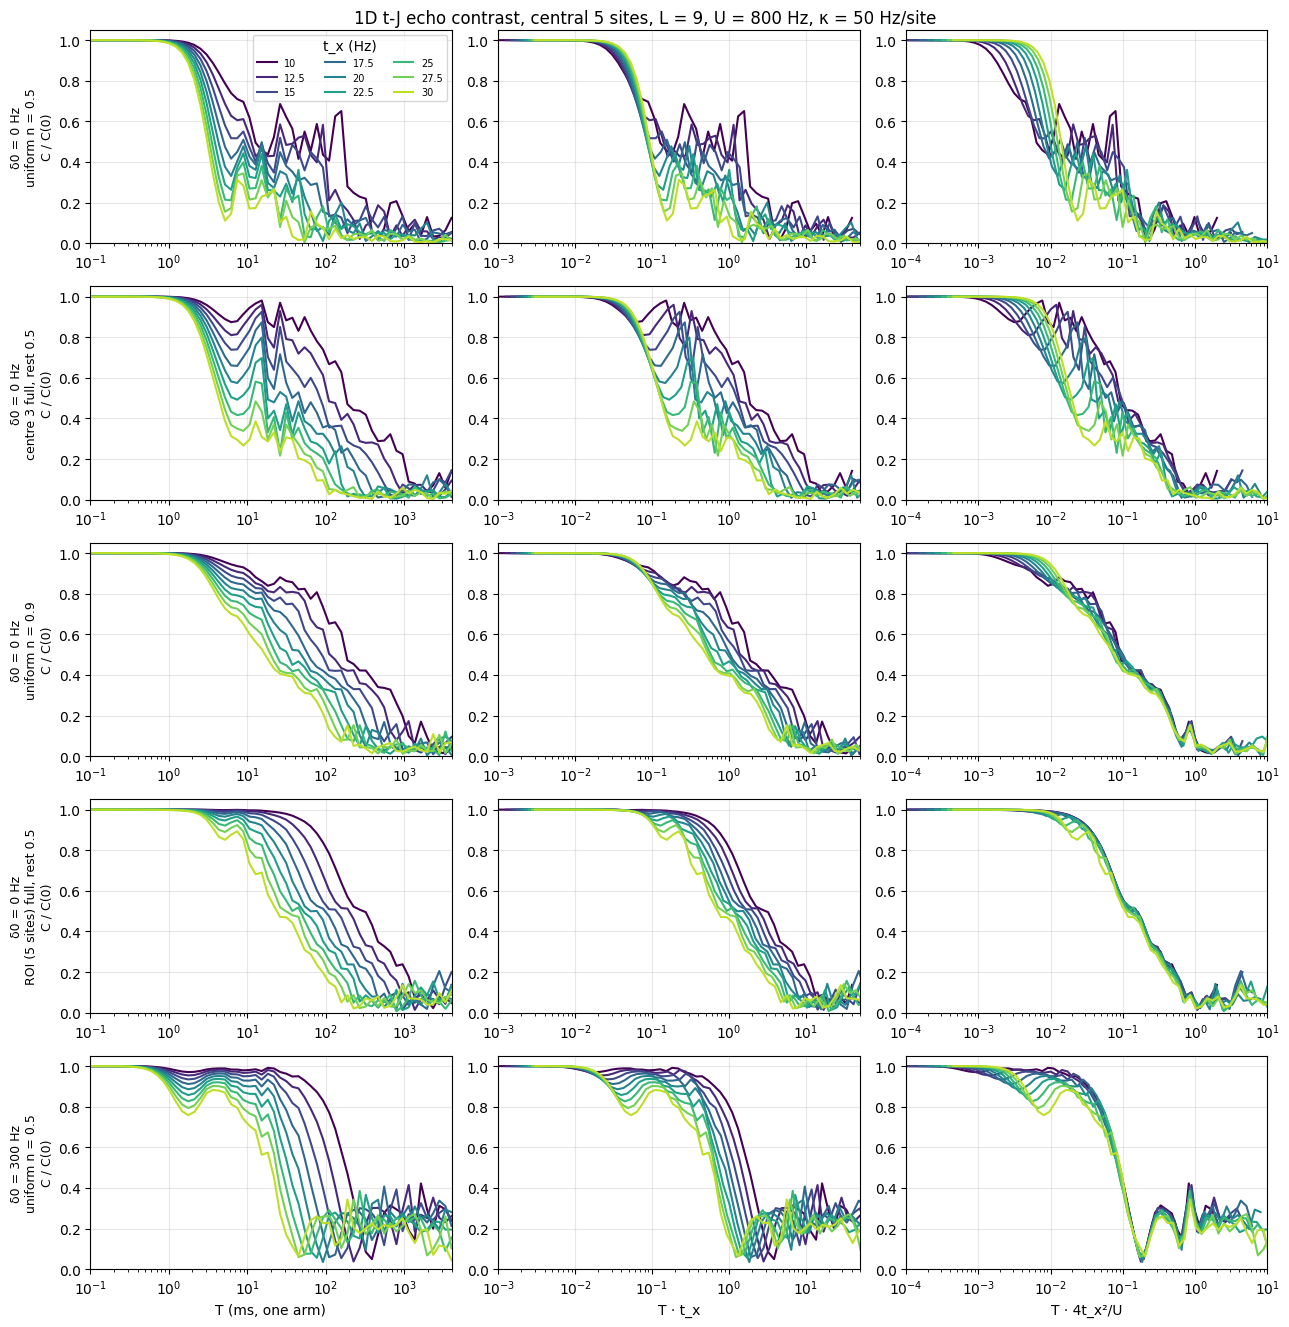

In [8]:
xs = np.arange(L) - (L - 1) / 2
rows = [(0, "uniform n = 0.5", weights(L, 0.5)),
        (0, "centre 3 full, rest 0.5", weights(L, np.where(np.abs(xs) <= 1, 1.0, 0.5))),
        (0, "uniform n = 0.9", weights(L, 0.9)),
        (0, "ROI (5 sites) full, rest 0.5", weights(L, np.where(np.abs(xs) <= 2, 1.0, 0.5))),
        (300, "uniform n = 0.5", weights(L, 0.5))]
cols = plt.cm.viridis(np.linspace(0, 0.9, len(TX)))
fig, ax = plt.subplots(len(rows), 3, figsize=(13, 2.7 * len(rows)))
for r, (d0, name, w) in enumerate(rows):
    for tx, col in zip(TX, cols):
        C = contrast(*RUNS[d0][tx], w)[1:]
        ax[r, 0].semilogx(T[1:] * 1e3, C, color=col, label=f"{tx:g}")
        ax[r, 1].semilogx(T[1:] * tx, C, color=col)
        ax[r, 2].semilogx(T[1:] * 4 * tx**2 / U, C, color=col)
    ax[r, 0].set_ylabel(f"δ0 = {d0} Hz\n{name}\nC / C(0)", fontsize=9)
    for a in ax[r]:
        a.set_ylim(0, 1.05); a.grid(alpha=0.3)
    ax[r, 0].set_xlim(0.1, 4000); ax[r, 1].set_xlim(1e-3, 50); ax[r, 2].set_xlim(1e-4, 10)
ax[-1, 0].set_xlabel("T (ms, one arm)"); ax[-1, 1].set_xlabel("T · t_x"); ax[-1, 2].set_xlabel("T · 4t_x²/U")
ax[0, 0].legend(title="t_x (Hz)", fontsize=7, ncol=3)
fig.suptitle(f"1D t-J echo contrast, central 5 sites, L = {L}, U = {U:g} Hz, κ = {KAPPA:g} Hz/site")
fig.tight_layout(); fig.savefig("fig_collapse_curves.png", dpi=110); plt.show()

## 8. How the collapse exponent is chosen

No function is fitted. The exponent $a$ is the one that makes the nine curves overlap best on the axis $T t_x^a$, the same test as judging a collapse by eye:

1. plot each curve against $\log T + a\log t_x$;
2. interpolate all curves onto a common 400-point grid and take the mean curve;
3. keep the grid points where the mean curve lies in the window, $C/C(0)$ from 0.98 down to 0.7, 0.5 or 0.2;
4. score $a$ by the rms spread of the curves about the mean at those points;
5. scan $a$ from 0 to 3 in steps of 0.05 and keep the minimum.

The window matters. With holes, the decay has two stages: hole hopping first (scales as $t_x$), then superexchange (as $t_x^2$). The grid is even in $\log T$ and the late stage lasts longer in $\log T$, so a deep window weights it more. The minimum is shallow: $a = 1$ and $a = 2$ often differ by only 20–30% in spread, so exponents near 1.5 are uncertain by several tenths.

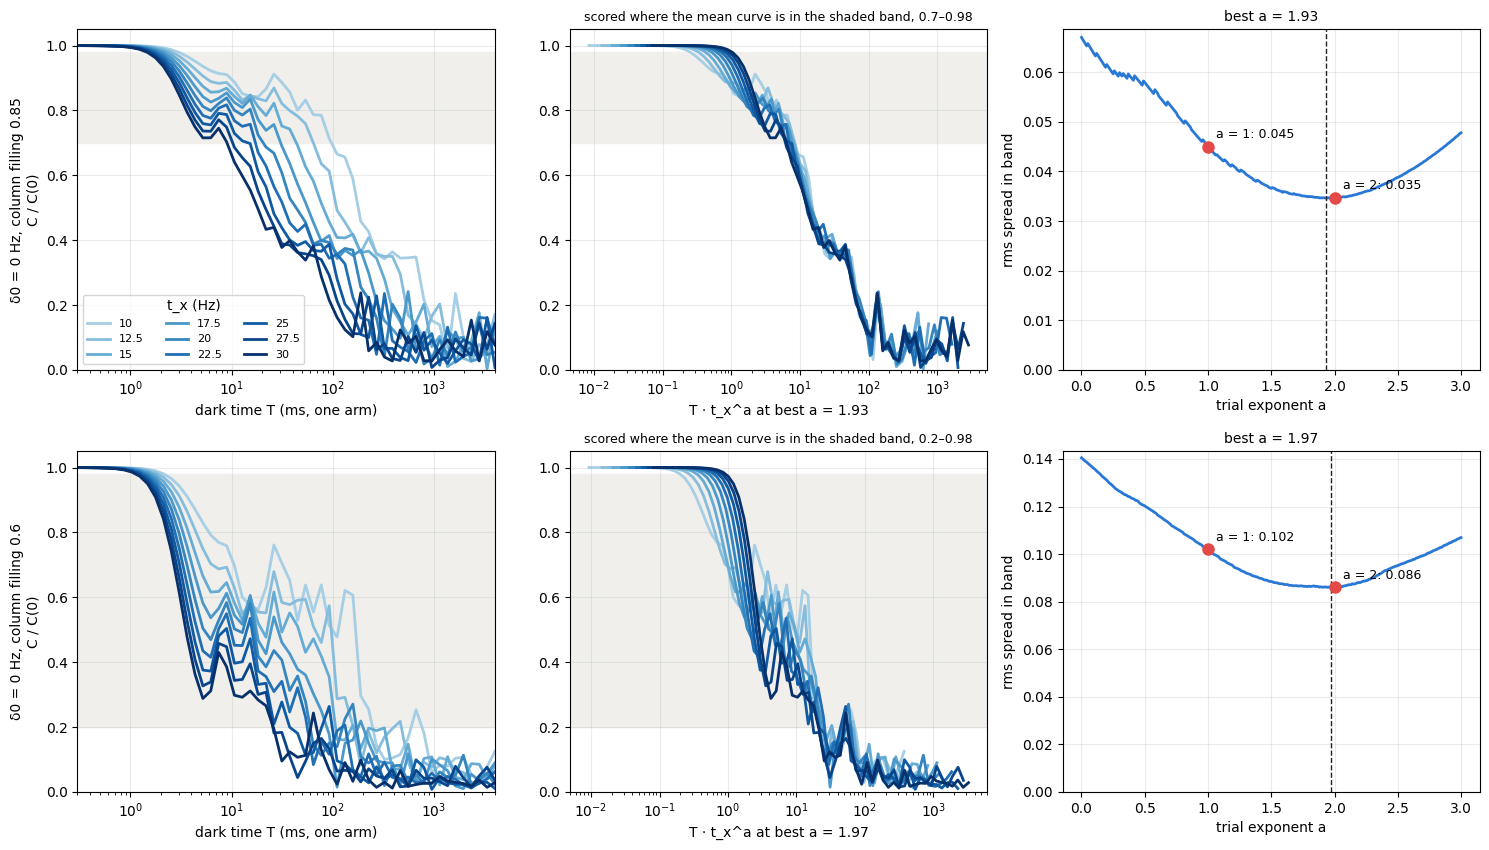

In [12]:
A_GRID = np.linspace(0, 3, 61)

def spread(runs, w, a, lo, hi=0.98):
    xs_, cs_ = [], []
    for tx, (O, n) in runs.items():
        xs_.append(np.log(T[1:]) + a * np.log(tx))
        cs_.append(contrast(O, n, w)[1:])
    g = np.linspace(max(x[0] for x in xs_), min(x[-1] for x in xs_), 400)
    M = np.array([np.interp(g, x, c) for x, c in zip(xs_, cs_)])
    m = M.mean(0)
    sel = (m < hi) & (m > lo)
    return np.sqrt(((M[:, sel] - m[sel]) ** 2).mean()) if sel.sum() >= 5 else np.nan

def best_a(runs, w, lo, grid=A_GRID):
    s = np.array([spread(runs, w, a, lo) for a in grid])
    return grid[np.nanargmin(s)], s

demo = [(0, 0.85, 0.7), (0, 0.60, 0.2)]          # (delta0, column filling, window lower edge)
fine = np.linspace(0, 3, 301)
bcols = plt.cm.Blues(np.linspace(0.35, 1.0, len(TX)))
fig, ax = plt.subplots(len(demo), 3, figsize=(15, 4.3 * len(demo)))
for r, (d0, cf, lo) in enumerate(demo):
    w = column_weights(L, cf)
    ab, s = best_a(RUNS[d0], w, lo, fine)
    for tx, col in zip(TX, bcols):
        C = contrast(*RUNS[d0][tx], w)[1:]
        ax[r, 0].semilogx(T[1:] * 1e3, C, color=col, lw=2, label=f"{tx:g}")
        ax[r, 1].semilogx(T[1:] * tx**ab, C, color=col, lw=2)
    for a_ in ax[r, :2]:
        a_.axhspan(lo, 0.98, color="#f0efec", zorder=0); a_.set_ylim(0, 1.05); a_.grid(alpha=0.25)
    ax[r, 0].set_xlim(0.3, 4000)
    ax[r, 0].set_ylabel(f"δ0 = {d0} Hz, column filling {cf}\nC / C(0)")
    ax[r, 0].set_xlabel("dark time T (ms, one arm)")
    ax[r, 1].set_xlabel(f"T · t_x^a at best a = {ab:.2f}")
    ax[r, 1].set_title(f"scored where the mean curve is in the shaded band, {lo}–0.98", fontsize=9)
    ax[r, 2].plot(fine, s, color="#2a78d6", lw=2); ax[r, 2].axvline(ab, color="#222", ls="--", lw=1)
    for a_ref in (1, 2):
        v = np.interp(a_ref, fine, s)
        ax[r, 2].plot([a_ref], [v], "o", color="#e34948", ms=8)
        ax[r, 2].annotate(f"a = {a_ref}: {v:.3f}", (a_ref, v), textcoords="offset points", xytext=(6, 6), fontsize=9)
    ax[r, 2].set_xlabel("trial exponent a"); ax[r, 2].set_ylabel("rms spread in band")
    ax[r, 2].set_title(f"best a = {ab:.2f}", fontsize=10); ax[r, 2].set_ylim(0, None); ax[r, 2].grid(alpha=0.25)
ax[0, 0].legend(title="t_x (Hz)", fontsize=8, ncol=3, loc="lower left")
fig.tight_layout(); fig.savefig("fig_exponent_fit_demo.png", dpi=110); plt.show()

## 9. Best exponent against uniform filling

Uniform filling on every site, for four offsets. $a \approx 1$: the curves collapse on $T t_x$ (hole hopping); $a \approx 2$: on $T\cdot4t_x^2/U$ (superexchange).

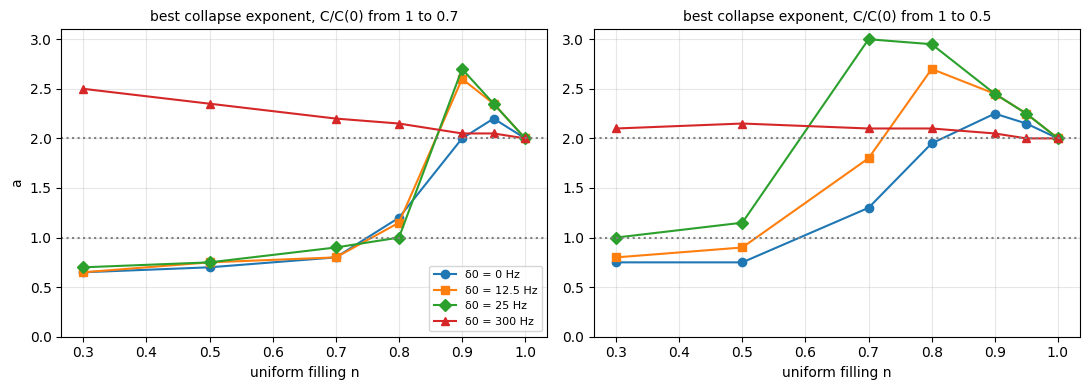

In [10]:
fills = [0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for d0, mk in zip([d for d in [0, 12.5, 25, 300] if d in RUNS], "osD^"):
    for k, lo in enumerate((0.7, 0.5)):
        ax[k].plot(fills, [best_a(RUNS[d0], weights(L, nf), lo)[0] for nf in fills], marker=mk, label=f"δ0 = {d0:g} Hz")
        ax[k].set_title(f"best collapse exponent, C/C(0) from 1 to {lo}", fontsize=10)
for a_ in ax:
    a_.axhline(1, color="gray", ls=":"); a_.axhline(2, color="gray", ls=":")
    a_.set_xlabel("uniform filling n"); a_.set_ylim(0, 3.1); a_.grid(alpha=0.3)
ax[0].set_ylabel("a"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("fig_exponent_vs_filling.png", dpi=110); plt.show()

## 10. Exponent map: $\delta_0$ against z-averaged column filling

Colour = best exponent $a$, centred on 1.5: blue collapses on $T t_x$, red on $T t_x^2$. The black line is $a = 1.5$. One panel per fit window. Up to $\delta_0 = 100$ Hz the trap centre stays inside the readout region ($x = -\delta_0/\kappa = -2$ sites at 100 Hz), so a bond with $|\Delta| = 25$ Hz remains in it.

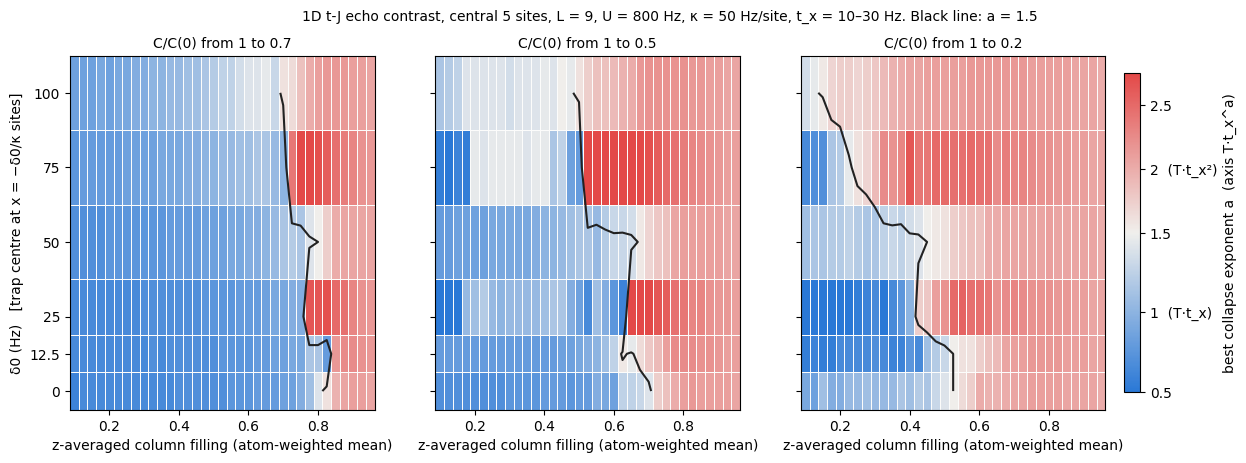

column filling where a first reaches 1.5:
delta0 (Hz) | window to 0.7 | window to 0.5 | window to 0.2
          0 |         0.825 |         0.725 |         0.525
       12.5 |         0.850 |         0.625 |         0.525
         25 |         0.775 |         0.650 |         0.425
         50 |         0.800 |         0.675 |         0.450
         75 |         0.725 |         0.525 |         0.250
        100 |         0.700 |         0.450 |         0.150


In [11]:
FILL = np.round(np.arange(0.10, 0.951, 0.025), 3)
WINDOWS = [0.7, 0.5, 0.2]
Wcol = [column_weights(L, f) for f in FILL]
AMAP = np.array([[[best_a(RUNS[d0], w, lo)[0] for w in Wcol] for d0 in D0_MAP] for lo in WINDOWS])
np.savez(f"exponent_map_L{L}.npz", A=AMAP, delta0=D0_MAP, filling=FILL, windows=WINDOWS)

def edges(v):
    v = np.asarray(v, float); m = (v[1:] + v[:-1]) / 2
    return np.concatenate([[v[0] - (m[0] - v[0])], m, [v[-1] + (v[-1] - m[-1])]])

cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
norm = TwoSlopeNorm(vmin=0.5, vcenter=1.5, vmax=2.75)
fig, ax = plt.subplots(1, len(WINDOWS), figsize=(16, 4.6), sharey=True)
for k, lo in enumerate(WINDOWS):
    pc = ax[k].pcolormesh(edges(FILL), edges(D0_MAP), AMAP[k], cmap=cmap, norm=norm, edgecolors="#fcfcfb", linewidth=0.5)
    ax[k].contour(FILL, D0_MAP, AMAP[k], levels=[1.5], colors="#222", linewidths=1.5)
    ax[k].set_title(f"C/C(0) from 1 to {lo}", fontsize=10)
    ax[k].set_xlabel("z-averaged column filling (atom-weighted mean)")
    ax[k].set_yticks(D0_MAP); ax[k].set_yticklabels([f"{d:g}" for d in D0_MAP])
ax[0].set_ylabel("δ0 (Hz)   [trap centre at x = −δ0/κ sites]")
cb = fig.colorbar(pc, ax=ax, shrink=0.9, pad=0.015, ticks=[0.5, 1, 1.5, 2, 2.5])
cb.ax.set_yticklabels(["0.5", "1  (T·t_x)", "1.5", "2  (T·t_x²)", "2.5"])
cb.set_label("best collapse exponent a  (axis T·t_x^a)")
fig.suptitle(f"1D t-J echo contrast, central 5 sites, L = {L}, U = {U:g} Hz, κ = {KAPPA:g} Hz/site, t_x = 10–30 Hz. Black line: a = 1.5", fontsize=10)
fig.savefig(f"exponent_map_L{L}.png", dpi=110, bbox_inches="tight"); plt.show()

print("column filling where a first reaches 1.5:")
print("delta0 (Hz) | " + " | ".join(f"window to {lo}" for lo in WINDOWS))
for i, d0 in enumerate(D0_MAP):
    cells = []
    for k in range(len(WINDOWS)):
        j = np.where(AMAP[k, i] >= 1.5)[0]
        cells.append(f"{FILL[j[0]]:.3f}" if len(j) else "  —  ")
    print(f"{d0:11g} | " + " | ".join(f"{c:>13s}" for c in cells))

## Limitations

| Limitation | Effect |
|---|---|
| Atoms start on definite sites | Changes the early drop near bonds with $t_x > \Delta_j$ if loading is adiabatic |
| Plain t-J: no three-site terms, no doublons | Misses $t^2/U$ corrections to hole motion; fails if $\lvert U-\Delta_j\rvert$ approaches $t_x$ |
| 1D only ($t_y = t_z = 0$) | No Vy dependence except through $U$ or loading |
| Same $t_x$, $U$, $\kappa$ for every $z$ | Ignores beam-envelope changes along $z$ |
| Instantaneous pulses | Matters if the pulse length approaches the hole-hopping drop (3–10 ms per arm) |
| $L = 9$ | Late times (after $C/C(0)\approx0.5$) are not converged in chain length; $L = 7$ and $L = 9$ give the same $a = 1.5$ boundary |
| One $U$ (800 Hz) | $U$ dependence not tested |